# 03 · Feature Engineering

## What this notebook does
Notebook 02 produced one clean row per hour. Here we turn it into the **inputs (X) and targets (y)** the model learns from.
We forecast the speed at Mahmutbey **1, 2 and 3 hours ahead**, so we build one dataset per horizon.

Every feature comes from a finding in 01 or a decision in 02. The most important rule is about **time**:
a feature may only contain information that is really available when the forecast is made.

| Group | Features | Why (from 01 / 02) |
|---|---|---|
| Speed history | current speed, lags 1–2 h, change in the last hour, rolling mean and variability (3, 6, 24 h) | Strong short-term memory (lag-1 autocorrelation 0.92) |
| Daily and weekly memory | speed at the same hour yesterday and last week (relative to the target hour) | Autocorrelation peaks at 24 h and 168 h |
| Typical speed | median speed for the target weekday and hour; how far the current speed is from normal | Two regimes; tells the model what "normal" is |
| Time | hour and weekday (sin/cos), weekend flag, hour of week (0–167) | Weekly pattern in the heatmap |
| Calendar | holidays, first holiday day, half days, admin leave, Ramadan, iftar, school days, fuel events | Iftar and holiday effects |
| Weather | temperature, rain, snowfall, wind at the forecast origin; rain in the last 3 hours | Rain and snow slow traffic |
| Neighbours | current speed and last-hour change of the 6 neighbour cells | Spatial information (value tested later) |
| Data quality | was the current speed filled? share of filled hours in the last 24 h | Lets the model trust filled inputs less |
| Vehicles | current vehicle count | Helps with the regime (capacity drop) |

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import ROOT, FIG_DIR
from src.features import HORIZONS, horizon_dataset, past_features

BLUE, ORANGE, GREY='#2E6FBA', '#D9822B', '#8A8F98'
plt.rcParams.update({
    'figure.dpi':110, 'savefig.dpi':300, 'savefig.bbox':'tight',
    'font.family':'serif', 'font.size':10,
    'axes.spines.top':False, 'axes.spines.right':False,
    'axes.grid':True, 'grid.color':'#E5E5E5', 'grid.linewidth':0.6,
})
def save(fig, name):
    fig.savefig(FIG_DIR/f'{name}.png')

df=pd.read_parquet(ROOT/'data'/'processed'/'dataset.parquet')
data={h:horizon_dataset(df, h) for h in HORIZONS}
X1, y1, meta1=data[1]
print(f'{X1.shape[1]} features per row')

49 features per row


## 1 · What is known at forecast time?

> 🔍 **Why this figure?** This is the rule behind every feature. Each row of the dataset is a **forecast origin** *t*:
> the last hour whose data has arrived. The target is the measured speed at *t + h*.
>
> - **Past information** (speeds, weather, neighbours) is used **up to t only**.
> - **Known-ahead information** (time of day, holidays, iftar, fuel events) is taken **at the target hour t + h**,
>   because it is already known when the forecast is made.
> - "Same hour yesterday / last week" is measured from the target hour (t + h − 24 and t + h − 168), which is still in the past for h ≤ 3.

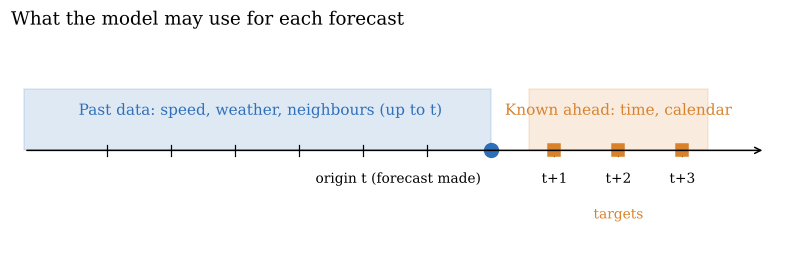

In [2]:
fig, ax=plt.subplots(figsize=(9, 2.6))
ax.axis('off')
ax.set_xlim(-7.5, 4.5); ax.set_ylim(-1.6, 1.8)
ax.annotate('', xy=(4.3, 0), xytext=(-7.3, 0), arrowprops=dict(arrowstyle='->', color='black', lw=1))
for x in range(-6, 4):
    ax.plot([x, x], [-0.08, 0.08], color='black', lw=0.8)
ax.axvspan(-7.3, 0, ymin=0.47, ymax=0.75, color=BLUE, alpha=0.15)
ax.text(-3.6, 0.55, 'Past data: speed, weather, neighbours (up to t)', ha='center', color=BLUE)
ax.axvspan(0.6, 3.4, ymin=0.47, ymax=0.75, color=ORANGE, alpha=0.15)
ax.text(2, 0.55, 'Known ahead: time, calendar', ha='center', color=ORANGE)
ax.plot(0, 0, 'o', color=BLUE, ms=9)
ax.text(-0.15, -0.5, 'origin t (forecast made)', ha='right', fontsize=9)
for h in HORIZONS:
    ax.plot(h, 0, 's', color=ORANGE, ms=8)
    ax.text(h, -0.5, f't+{h}', ha='center', fontsize=9)
ax.text(2, -1.05, 'targets', ha='center', color=ORANGE, fontsize=9)
ax.set_title('What the model may use for each forecast', loc='left')
save(fig, 'fig15_information_timeline'); plt.show()

## 2 · Check that no future data leaks into the features

> 🔍 **Why?** A leak is easy to make and hard to see: one wrong `shift` and the model "sees" the answer. The score then
> looks great but means nothing. We test this directly: for random origins *t*, we rebuild the past features using
> **only the data up to t** and check that they are identical to the features in the full table.

In [3]:
rng=np.random.default_rng(1907)
past_cols=past_features(df).columns
origins=rng.choice(X1.index, 200, replace=False)
mismatch=0
for t in origins:
    rebuilt=past_features(df.loc[:t]).loc[t, past_cols].astype(float).values
    mismatch+=int(not np.allclose(rebuilt, X1.loc[t, past_cols].astype(float).values, equal_nan=True))
print(f'Origins tested: {len(origins)} | features that changed when the future was removed: {mismatch}')

Origins tested: 200 | features that changed when the future was removed: 0


**Result.** The features do not change when all future data is removed, so they only use information available at time *t*.

## 3 · Dataset size per horizon

Rows are kept only if the **target hour has a measured speed** (filled hours are never targets) and the input
features are complete (the first week of January is lost because the 168-hour lag needs one week of history).
The split is decided by the **target time**.

In [4]:
rows=[]
for h, (X, y, meta) in data.items():
    counts=meta['split'].value_counts()
    rows.append({'horizon':f'{h} h', 'features':X.shape[1], 'train':counts['train'], 'val':counts['val'], 'test':counts['test']})
pd.DataFrame(rows).set_index('horizon')

,features,train,val,test
horizon,,,,
1 h,49,5148,1463,1249
2 h,49,5148,1463,1249
3 h,49,5148,1463,1249


## 4 · Which features carry information, and how does it fade with the horizon?

> 🔍 **Why this plot?** Before training, we want a first, simple view of which features are related to the target,
> and how this changes when we look further ahead. We use the correlation with the target on the **training data only**.
> This is not a model result; it only shows linear relationships, one feature at a time.

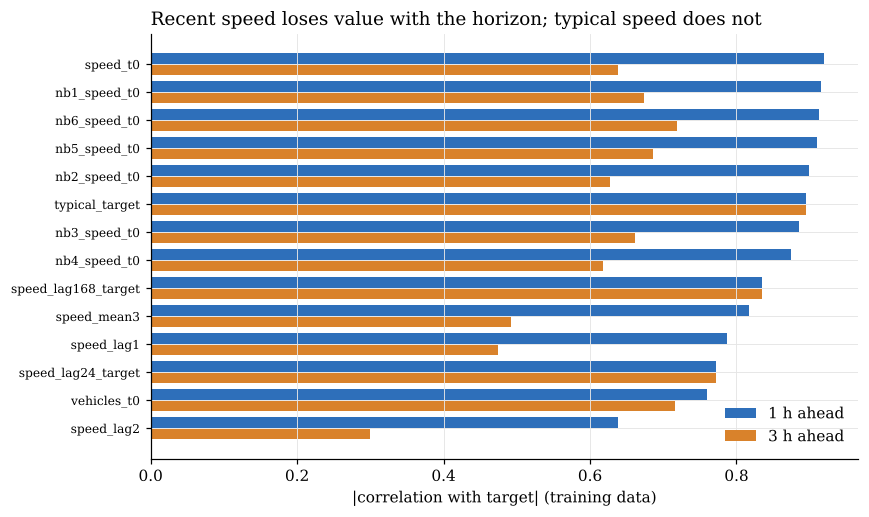

,1,2,3
speed_t0,0.920,0.788,0.638
nb1_speed_t0,0.915,0.808,0.674
nb6_speed_t0,0.913,0.836,0.718
nb5_speed_t0,0.910,0.817,0.686
nb2_speed_t0,0.898,0.774,0.627
typical_target,0.895,0.895,0.895
nb3_speed_t0,0.886,0.779,0.661
nb4_speed_t0,0.875,0.753,0.618
speed_lag168_target,0.835,0.835,0.835
speed_mean3,0.817,0.662,0.492


In [5]:
corr={}
for h, (X, y, meta) in data.items():
    tr=meta['split']=='train'
    corr[h]=X[tr].corrwith(y[tr]).abs()
corr=pd.DataFrame(corr)
top=corr[1].sort_values(ascending=False).head(14).index

fig, ax=plt.subplots(figsize=(8, 4.8))
ypos=np.arange(len(top))
ax.barh(ypos-0.2, corr.loc[top, 1], height=0.38, color=BLUE, label='1 h ahead')
ax.barh(ypos+0.2, corr.loc[top, 3], height=0.38, color=ORANGE, label='3 h ahead')
ax.set_yticks(ypos); ax.set_yticklabels(top, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel('|correlation with target| (training data)')
ax.set_title('Recent speed loses value with the horizon; typical speed does not', loc='left')
ax.legend(frameon=False)
fig.tight_layout(); save(fig, 'fig16_feature_correlation'); plt.show()

corr.loc[top].round(3)

**Findings.** For 1 hour ahead, the current speed (r = 0.92) and the neighbour speeds are the strongest signals.
At 3 hours ahead the current speed drops to 0.64, while the typical speed for the target hour (0.90) and the speed at the
same hour last week (0.84) do not change. The near future looks like the present; the further future looks like the usual pattern.

One detail is worth noting: at 3 hours ahead, the **neighbours keep more information than Mahmutbey's own speed**
(e.g. `nb6` 0.72 vs. 0.64). In 01 we found no clear lead at the hourly scale, but this suggests the neighbours may still
help at longer horizons, perhaps because they describe the state of the wider road network.

> ➡️ **What it means for the model:** for longer horizons the model will rely more on the weekly pattern and the
> calendar. The neighbour comparison in notebook 04 should be done **for each horizon separately**.

## 5 · Input for sequence models

The table above gives one row per forecast origin and is used directly by tree-based models (for example XGBoost).
Sequence models such as the LSTM also read a **window of past hours**. They will use the same columns: the window
for origin *t* is built from rows *t − W + 1 … t*. Because every row only contains information up to its own time,
the windows are leak-free as well. The windows are built in notebook 04.

## Features we considered but did not use

- **Hand-made peak-hour flags** (e.g. shopping-mall peak, bus terminal peak, shift changes in the industrial zone, Friday
  evening exit). Each of them is a fixed set of weekday–hour combinations, so the model already gets this information
  from the hour-of-week feature. They would only repeat it.
- **Black Friday week and football derby days.** In the data, these days are not different from normal days at
  Mahmutbey (Black Friday week: −0.4 km/h; the three derby days point in different directions).
- **Month and a time trend.** With only one year of data, the test months (November–December) never appear in training,
  so the model could not learn what these values mean.
- **Minimum and maximum speed.** Too noisy (see 01, section 1.3).